# Stage 1.5: geometry + Laplacian eigenvectors — frozen and joint variants

Choose `training_mode="frozen"` to train only the classifier on cached Stage 1 CNN embeddings, or `training_mode="joint"` to fine-tune the CNN and classifier together. Both concatenate each face's geometry embedding with its fixed per-solid Laplacian features. Both start from the same baseline CNN and the same seeded classifier initialization. There is **no message passing**, edge CNN, or global shape embedding in this stage.

The normalized Laplacian and sign augmentation follow `notebooks/07_Graph_Transformers/code02_dgl_solution.ipynb` in the course repository. We use `torch.linalg.eigh` for a real symmetric Laplacian rather than the general `eig` solver in the tutorial. Compute features separately for each solid, never on a batched disconnected graph. Random signs address sign ambiguity only; rotations within repeated eigenspaces remain a limitation.

Run preparation and training cells yourself. The notebook has not been trained. Use the `gnn_project` kernel. Stage 1's final checkpoint must be available locally or on the VM at the path below.

Final prediction exports include ordered sample IDs, per-row sample indices and zero-based graph face indices. These are checked against annotation labels; STEP viewer face identity is a separate mapping.


In [2]:
import os
os.environ["DGLBACKEND"] = "pytorch"

import csv
import hashlib
import json
from pathlib import Path

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm

from uvnet_project.checkpointing import (
    seed_everything, save_training_checkpoint, load_training_checkpoint,
)
from uvnet_project.face_cnn import FaceCNN
from uvnet_project.classifier import Classifier
from uvnet_project.laplacian import laplacian_positional_encoding
from uvnet_project.load_mfcad import DATA_DIR, _load_sample, _load_splits
from uvnet_project.evaluation import evaluate

from uvnet_project.geometry_laplacian import FaceLaplacianBatch, GeometryLaplacianClassifier


## Reproducibility and epoch-boundary resume

Set `seed` and `resume_checkpoint` in the settings cell. Fresh runs seed Python, NumPy, Torch CPU/CUDA before initializing weights and again when starting a fresh training run. The training cell creates a fresh model when `resume_checkpoint=None`.

After **every completed epoch**, `epoch_NNN/model_weights.pt` contains model weights; `epoch_NNN/checkpoint.pt` contains weights, optimizer, AMP scaler where used, seed, Python/NumPy/Torch CPU/CUDA RNG states, histories and configuration. Checkpoints are written atomically. Laplacian checkpoints also include the CNN state and baseline checkpoint hash; the feature cache must be retained to preserve eigenbases.

To resume: restart the kernel, set `resume_checkpoint` to the desired `checkpoint.pt`, run preparation cells, then the training cell. Set `num_epochs` to the **total target**, e.g. 20 to continue epoch 10 through epoch 20. Resume restores RNG states immediately before the epoch loop, rather than resetting the seed each epoch. Loss curves and step counts continue from the stored histories. A partial epoch is rerun from the most recent completed checkpoint. The same mode-specific run folder is reused. Resume rejects a different mode; earlier frozen-only checkpoints are treated as frozen.

Use the same dataset order, cached features, software, GPU and training settings for reproducible replay. Deterministic settings disable cuDNN autotuning and TF32; restart the kernel before using them if CUDA was already initialized. Existing checkpoints created before this change lack RNG states: they can supply weights, but cannot provide exact trajectory resume. Training has not been started by these edits.


## Settings and baseline checkpoint

Start with 8 eigenvectors (editable). Feature columns follow increasing eigenvalue; drop the zero eigenspace and zero-pad solids with too few nontrivial eigenvectors. The symmetric adjacency retains the dataset's edge multiplicities and self-loops; it is not simplified. Edge geometry is not used.

The classifier has the same two-layer structure and hidden width as the baseline, with a wider input. The checkpoint supplies the CNN dimensions; changing `pos_enc_dim` creates a different feature cache. Validation is the official validation split; test is not loaded. Matching experiment files are overwritten.


In [4]:
seed = 0
deterministic = True
# None starts a new seeded run. To resume, set the completed epoch checkpoint:
# resume_checkpoint = DATA_DIR.parent.parent / "results/laplacian_run_01/epoch_010/checkpoint.pt"
resume_checkpoint = None
seed_everything(seed, deterministic=deterministic)
project_dir = DATA_DIR.parent.parent
baseline_checkpoint = project_dir / "results/baseline_run_01/epoch_020/checkpoint.pt"
training_mode = "joint"  # "frozen" or "joint"; rerun from the top after changing
if training_mode not in ("frozen", "joint"):
    raise ValueError("training_mode must be frozen or joint.")
pos_enc_dim = 8
num_epochs = 20
batch_size = 128  # solids per training batch
learning_rate = 0.001
run_name = "laplacian_run_01" if training_mode == "frozen" else "laplacian_joint_run_01"
run_dir = project_dir / "results" / run_name
cache_dir = project_dir / "data/feature_cache"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

if not baseline_checkpoint.is_file():
    raise FileNotFoundError(f"Copy the final baseline checkpoint here first: {baseline_checkpoint}")
if min(pos_enc_dim, num_epochs, batch_size) < 1:
    raise ValueError("Dimensions, epoch count and batch/checkpoint sizes must be positive.")
checkpoint = torch.load(baseline_checkpoint, map_location="cpu", weights_only=True)
config = checkpoint["config"]
embedding_dim = config["embedding_dim"]
hidden_dim = config["hidden_dim"]
num_classes = config["num_classes"]
in_channels = config["in_channels"]
baseline_hash = hashlib.sha256(baseline_checkpoint.read_bytes()).hexdigest()
print("Device:", device, "Classifier input:", embedding_dim + pos_enc_dim)


Device: cuda Classifier input: 72


/home/yongjun23/miniconda3/envs/gnn_project/lib/python3.11/site-packages/torch/_utils.py:831: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. This should only matter to you if you are using storages directly.  To access UntypedStorage directly, use tensor.untyped_storage() instead of tensor.storage()
  return self.fget.__get__(instance, owner)()


## Restore the baseline CNN and choose the trainable model

Frozen mode caches CNN embeddings and trains only the MLP. Joint mode restores a trainable CNN, recomputes geometry every batch, and backpropagates through both CNN and classifier. Its batch normalization updates during training. The Laplacian is fixed in both modes. Restart from the settings when changing modes; results folders are separate.


In [11]:
# Baseline was nn.Sequential(face_cnn, classifier): prefix 0. selects the CNN.
cnn_state = {key.removeprefix("0."): value
             for key, value in checkpoint["model_state_dict"].items()
             if key.startswith("0.")}
face_cnn = FaceCNN(embedding_dim=embedding_dim, in_channels=in_channels)
face_cnn.load_state_dict(cnn_state, strict=True)
face_cnn.requires_grad_(False)
face_cnn = face_cnn.to(device).eval()  # used only to prepare frozen-mode embeddings


def build_model():
    # Initialize the same head first in either mode, under the same seed.
    head = Classifier(embedding_dim + pos_enc_dim, hidden_dim, num_classes)
    if training_mode == "frozen":
        return head.to(device)
    # Preserve the head-only variant's RNG position for shuffling and signs.
    with torch.random.fork_rng(devices=[]):
        encoder = FaceCNN(embedding_dim=embedding_dim, in_channels=in_channels)
    encoder.load_state_dict(cnn_state, strict=True)
    encoder.requires_grad_(True)
    return GeometryLaplacianClassifier(encoder, head).to(device)


seed_everything(seed, deterministic=deterministic)
model = build_model()
print(model)
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))


GeometryLaplacianClassifier(
  (face_cnn): FaceCNN(
    (conv1): Sequential(
      (0): Conv2d(7, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): LeakyReLU(negative_slope=0.01)
    )
    (conv2): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): LeakyReLU(negative_slope=0.01)
    )
    (conv3): Sequential(
      (0): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): LeakyReLU(negative_slope=0.01)
    )
    (pool): AdaptiveAvgPool2d(output_size=(1, 1))
    (fc): Sequential(
      (0): Linear(in_features=256, out_features=64, bias=False)
      (1): BatchNorm1d(64, eps=1e-05, momentum=0.

## Prepare and cache per-solid features

Read graph/labels only during preprocessing. Cache one feature tensor and label tensor per solid, in official split order and original face order. Batch several solids for CNN inference, but compute Laplacian features on each solid individually. Cached eigenvector signs are kept fixed during evaluation.

The cache key includes the checkpoint hash, feature settings and ordered split IDs. If you modify the dataset files or the feature algorithm, delete the corresponding cache or change `cache_version`. Reusing a cache does not recompute eigenvectors and therefore preserves its stored eigenbases.

Joint mode caches face grids, Laplacian features and labels, **not geometry embeddings**. It reuses frozen-cache eigenbases when available, so the two experiments use the same topology coordinates. Retain the joint cache for exact resume.


In [12]:
@torch.no_grad()
def prepare_features(split, encode_batch_size=128):
    sample_ids = _load_splits()[split]
    metadata = dict(cache_version=1, baseline_hash=baseline_hash,
                    pos_enc_dim=pos_enc_dim, sample_ids=sample_ids,
                    embedding_dim=embedding_dim, in_channels=in_channels,
                    laplacian="symmetric_normalized_multiplicity_preserved")
    cache_key = hashlib.sha256(json.dumps(metadata, sort_keys=True).encode()).hexdigest()[:16]
    cache_path = cache_dir / f"{split}_{cache_key}.pt"
    if cache_path.is_file():
        cached = torch.load(cache_path, map_location="cpu", weights_only=True)
        if cached["metadata"] != metadata:
            raise ValueError("Feature cache metadata mismatch.")
        print("Using cache:", cache_path)
        return cached["samples"], sample_ids

    if resume_checkpoint is not None:
        raise FileNotFoundError(f"Retain the original feature cache for exact resume: {cache_path}")
    joint_path = cache_dir / f"joint_{split}_{cache_key}.pt"
    joint_cached = torch.load(joint_path, map_location="cpu", weights_only=True) if joint_path.is_file() else None
    if joint_cached is not None and joint_cached["metadata"] != metadata:
        raise ValueError("Joint input cache metadata mismatch.")
    face_cnn.eval()
    cached_samples = []
    for start in tqdm(range(0, len(sample_ids), encode_batch_size), desc=f"Cache {split}"):
        solids = [_load_sample(sid) for sid in sample_ids[start:start + encode_batch_size]]
        sizes = [solid["graph"].num_nodes() for solid in solids]
        grids = torch.cat([solid["graph"].ndata["x"] for solid in solids])
        grids = grids.permute(0, 3, 1, 2).contiguous().float().to(device)
        embeddings = face_cnn(grids).cpu().split(sizes)
        for offset, (solid, geometry) in enumerate(zip(solids, embeddings)):
            lap_features = (joint_cached["samples"][start + offset][1].clone() if joint_cached is not None
                            else laplacian_positional_encoding(solid["graph"], pos_enc_dim))
            features = torch.cat((geometry, lap_features), dim=1)
            labels = torch.tensor([face["segment"]["index"] for face in solid["faces"]],
                                  dtype=torch.long)
            assert features.shape == (len(labels), embedding_dim + pos_enc_dim)
            cached_samples.append((features, labels))
    cache_dir.mkdir(parents=True, exist_ok=True)
    torch.save(dict(metadata=metadata, samples=cached_samples), cache_path)
    print("Saved cache:", cache_path)
    return cached_samples, sample_ids


@torch.no_grad()
def prepare_joint_inputs(split):
    sample_ids = _load_splits()[split]
    metadata = dict(cache_version=1, baseline_hash=baseline_hash,
                    pos_enc_dim=pos_enc_dim, sample_ids=sample_ids,
                    embedding_dim=embedding_dim, in_channels=in_channels,
                    laplacian="symmetric_normalized_multiplicity_preserved")
    cache_key = hashlib.sha256(json.dumps(metadata, sort_keys=True).encode()).hexdigest()[:16]
    cache_path = cache_dir / f"joint_{split}_{cache_key}.pt"
    frozen_path = cache_dir / f"{split}_{cache_key}.pt"
    if cache_path.is_file():
        cached = torch.load(cache_path, map_location="cpu", weights_only=True)
        if cached["metadata"] != metadata:
            raise ValueError("Joint input cache metadata mismatch.")
        print("Using joint input cache:", cache_path)
        return cached["samples"], sample_ids
    if resume_checkpoint is not None:
        raise FileNotFoundError(f"Retain joint input cache for exact resume: {cache_path}")

    # Reuse the frozen variant's exact eigenbases when that cache is available.
    frozen = torch.load(frozen_path, map_location="cpu", weights_only=True) if frozen_path.is_file() else None
    if frozen is not None and frozen["metadata"] != metadata:
        raise ValueError("Frozen feature cache metadata mismatch.")
    samples = []
    for index, sample_id in enumerate(tqdm(sample_ids, desc=f"Cache joint {split}")):
        solid = _load_sample(sample_id)
        grids = solid["graph"].ndata["x"].permute(0, 3, 1, 2).contiguous().float()
        lap = (frozen["samples"][index][0][:, embedding_dim:].clone() if frozen is not None
               else laplacian_positional_encoding(solid["graph"], pos_enc_dim))
        labels = torch.tensor([face["segment"]["index"] for face in solid["faces"]], dtype=torch.long)
        samples.append((grids, lap, labels))
    cache_dir.mkdir(parents=True, exist_ok=True)
    temporary = cache_path.with_suffix(".pt.tmp")
    torch.save(dict(metadata=metadata, samples=samples), temporary)
    os.replace(temporary, cache_path)
    return samples, sample_ids


prepare_inputs = prepare_features if training_mode == "frozen" else prepare_joint_inputs
train_samples, train_ids = prepare_inputs("train")
validation_samples, validation_ids = prepare_inputs("validation")


Cache joint train:   0%|          | 0/9277 [00:00<?, ?it/s]

Cache joint validation:   0%|          | 0/3090 [00:00<?, ?it/s]

## Batches and sign augmentation

Draw one independent sign for **each eigenvector of each solid** every time a training solid is fetched. Broadcast that sign over all its faces. Never flip each face independently. Geometry columns are unchanged. Training-evaluation and validation loaders read the same cached features without augmentation.


In [13]:
class FeatureDataset(Dataset):
    def __init__(self, samples, augment=False):
        self.samples = samples
        self.augment = augment

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        if training_mode == "joint":
            grids, lap, labels = self.samples[index]
            if self.augment:
                signs = torch.randint(0, 2, (pos_enc_dim,)) * 2 - 1
                lap = lap * signs  # one sign per eigenvector, shared by all faces
            return (grids, lap), labels
        features, labels = self.samples[index]
        if self.augment:
            signs = torch.randint(0, 2, (pos_enc_dim,)) * 2 - 1
            features = features.clone()
            features[:, embedding_dim:] *= signs
        return features, labels


def collate_features(batch):
    inputs, labels = zip(*batch)
    if training_mode == "joint":
        grids, lap = zip(*inputs)
        inputs = FaceLaplacianBatch(torch.cat(grids), torch.cat(lap))
    else:
        inputs = torch.cat(inputs)
    return inputs, torch.cat(labels)


loader_options = dict(batch_size=batch_size, collate_fn=collate_features,
                      num_workers=0, pin_memory=device.type == "cuda")
train_loader = DataLoader(FeatureDataset(train_samples, augment=True), shuffle=True,
                          **loader_options)
train_evaluation_loader = DataLoader(FeatureDataset(train_samples), shuffle=False,
                                     **loader_options)
validation_loader = DataLoader(FeatureDataset(validation_samples), shuffle=False,
                               **loader_options)

inputs, labels = next(iter(validation_loader))
model.eval()
with torch.no_grad():
    logits = model(inputs.to(device))
assert logits.shape == (len(labels), num_classes)
assert torch.isfinite(logits).all()
print("Mode:", training_mode, "Logits:", tuple(logits.shape))


Mode: joint Logits: (2852, 16)


## Train the selected variant — run when ready

20 epochs, batch loss logging, validation at each checkpoint, and a final loss plot. Frozen mode trains only the MLP in float32. Joint mode trains CNN + MLP and uses AMP on CUDA; AMP scaler state is saved for resume. Training loss/accuracy are accumulated during the augmented training pass; validation uses fixed cached signs. Mean loss is weighted by face count. Only the final model's prediction probabilities are saved.


In [14]:
seed_everything(seed, deterministic=deterministic)
if resume_checkpoint is None:
    model = build_model()
use_amp = training_mode == "joint" and device.type == "cuda"
if use_amp:
    model = model.to(memory_format=torch.channels_last)
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
loss_fn = nn.CrossEntropyLoss()
history, batch_history = [], []
global_step = 0

run_config = dict(stage="laplacian", seed=seed, deterministic=deterministic,
                  embedding_dim=embedding_dim, pos_enc_dim=pos_enc_dim,
                  hidden_dim=hidden_dim, num_classes=num_classes,
                  learning_rate=learning_rate, batch_size=batch_size,
                  baseline_hash=baseline_hash, train_sample_ids=train_ids,
                  validation_sample_ids=validation_ids, training_mode=training_mode,
                  mixed_precision=use_amp)
start_epoch = 1
if resume_checkpoint is not None:
    resume_info = torch.load(resume_checkpoint, map_location="cpu", weights_only=True)
    saved_config = resume_info["config"]
    # Earlier frozen-only checkpoints did not record these two settings.
    if saved_config.get("training_mode", "frozen") != training_mode:
        raise ValueError("Cannot resume a different training mode.")
    if saved_config.get("mixed_precision", False) != use_amp:
        raise ValueError("Resume mixed-precision setting does not match.")
    expected_config = {key: value for key, value in run_config.items()
                       if key not in ("training_mode", "mixed_precision") or key in saved_config}
    restored = load_training_checkpoint(
        resume_checkpoint, model, optimizer, expected_config=expected_config, scaler=scaler if use_amp else None,
    )
    start_epoch = restored["epoch"] + 1
    history = restored["history"]
    batch_history = restored["batch_history"]
    global_step = batch_history[-1]["step"] if batch_history else 0
    if num_epochs < start_epoch:
        raise ValueError("Set num_epochs above the completed checkpoint epoch to continue training.")
    print(f"Resuming at epoch {start_epoch}; target is epoch {num_epochs}.")
run_dir.mkdir(parents=True, exist_ok=True)


@torch.no_grad()
def validation_metrics():
    model.eval()
    loss_total = torch.zeros((), device=device)
    correct_total = torch.zeros((), dtype=torch.long, device=device)
    faces = 0
    for features, labels in validation_loader:
        features, labels = features.to(device, non_blocking=True), labels.to(device, non_blocking=True)
        with torch.cuda.amp.autocast(enabled=use_amp):
            logits = model(features)
            loss = loss_fn(logits, labels)
        loss_total += loss * labels.numel()
        correct_total += (logits.argmax(1) == labels).sum()
        faces += labels.numel()
    return loss_total.item() / faces, correct_total.item() / faces


for epoch in tqdm(range(start_epoch, num_epochs + 1), desc="Epochs"):
    model.train()
    losses, correct, sizes = [], [], []
    for features, labels in tqdm(train_loader, desc=f"Epoch {epoch}: training", leave=False):
        features, labels = features.to(device, non_blocking=True), labels.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.cuda.amp.autocast(enabled=use_amp):
            logits = model(features)
            loss = loss_fn(logits, labels)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        losses.append(loss.detach())
        correct.append((logits.detach().argmax(1) == labels).sum())
        sizes.append(labels.numel())

    loss_values = torch.stack(losses).cpu().tolist()
    train_loss = sum(loss * size for loss, size in zip(loss_values, sizes)) / sum(sizes)
    train_accuracy = torch.stack(correct).sum().item() / sum(sizes)
    for batch_index, (batch_loss, count) in enumerate(zip(loss_values, sizes), 1):
        global_step += 1
        batch_history.append(dict(step=global_step, epoch=epoch, batch=batch_index,
                                  loss=batch_loss, faces=count))
    val_loss, val_accuracy = validation_metrics()
    row = dict(epoch=epoch, step=global_step, train_loss=train_loss,
               train_accuracy=train_accuracy, validation_loss=val_loss,
               validation_accuracy=val_accuracy)
    history.append(row)
    checkpoint_dir = run_dir / f"epoch_{epoch:03d}"
    checkpoint_dir.mkdir(parents=True, exist_ok=True)
    save_training_checkpoint(
        checkpoint_dir / "checkpoint.pt", model, optimizer, epoch=epoch, seed=seed,
        config={**run_config, "num_epochs": num_epochs, "checkpoint_every": 1},
        history=history, batch_history=batch_history, scaler=scaler if use_amp else None,
        extra=dict(baseline_checkpoint=str(baseline_checkpoint), baseline_hash=baseline_hash, face_cnn_state_dict=(model.face_cnn if training_mode == "joint" else face_cnn).state_dict(), train_sample_ids=train_ids, validation_sample_ids=validation_ids),
    )
    with (run_dir / "history.csv").open("w", newline="") as file:
        writer = csv.DictWriter(file, fieldnames=list(row))
        writer.writeheader()
        writer.writerows(history)
    tqdm.write(f"Epoch {epoch:02d}/{num_epochs} | train loss {train_loss:.4f}, "
               f"accuracy {train_accuracy:.2%} | validation loss {val_loss:.4f}, "
               f"accuracy {val_accuracy:.2%}")
    with (run_dir / "batch_loss.csv").open("w", newline="") as file:
        writer = csv.DictWriter(file, fieldnames=list(batch_history[0]))
        writer.writeheader()
        writer.writerows(batch_history)

final_train_results = evaluate(model, train_evaluation_loader,
                               checkpoint_dir / "train_predictions.pt", device=device,
                               sample_ids=train_ids, split="train")
final_validation_results = evaluate(model, validation_loader,
                                    checkpoint_dir / "validation_predictions.pt", device=device,
                                    sample_ids=validation_ids, split="validation")
print("Final predictions saved to:", checkpoint_dir)


Epochs:   0%|          | 0/20 [00:00<?, ?it/s]

Epoch 1: training:   0%|          | 0/73 [00:00<?, ?it/s]

Epoch 01/20 | train loss 1.1725, accuracy 67.56% | validation loss 0.5479, accuracy 81.43%


Epoch 2: training:   0%|          | 0/73 [00:00<?, ?it/s]

Epoch 02/20 | train loss 0.4147, accuracy 85.84% | validation loss 0.3682, accuracy 86.87%


...

Epoch 18/20 | train loss 0.1980, accuracy 92.30% | validation loss 0.2029, accuracy 92.26%


Epoch 19: training:   0%|          | 0/73 [00:00<?, ?it/s]

Epoch 19/20 | train loss 0.1949, accuracy 92.45% | validation loss 0.2035, accuracy 92.25%


Epoch 20: training:   0%|          | 0/73 [00:00<?, ?it/s]

Epoch 20/20 | train loss 0.1995, accuracy 92.32% | validation loss 0.2103, accuracy 91.96%
Final predictions saved to: /home/yongjun23/project/results/laplacian_joint_run_01/epoch_020


## Loss plot after training
Run after the training cell completes.


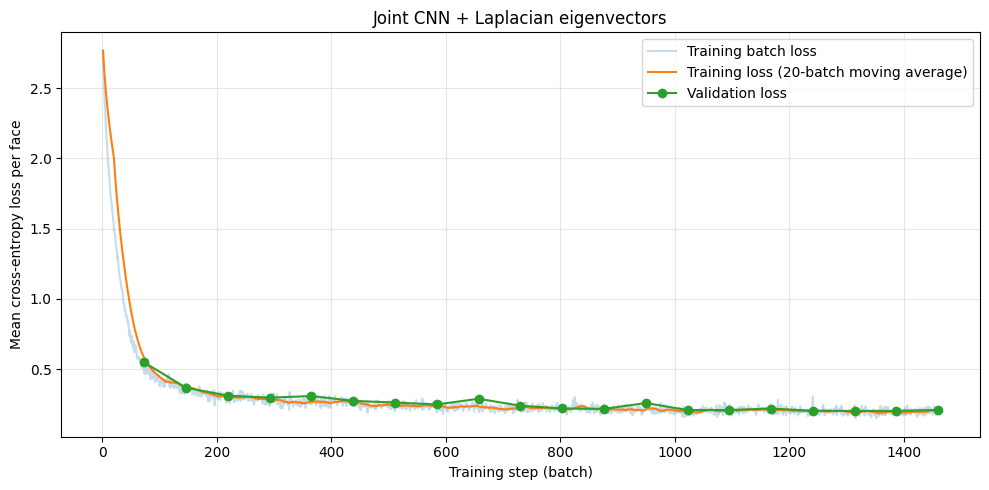

In [15]:
import matplotlib.pyplot as plt
import pandas as pd

batch_log = pd.DataFrame(batch_history)
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(batch_log["step"], batch_log["loss"], alpha=0.25, label="Training batch loss")
ax.plot(batch_log["step"], batch_log["loss"].rolling(20, min_periods=1).mean(),
        label="Training loss (20-batch moving average)")
ax.plot([row["step"] for row in history],
        [row["validation_loss"] for row in history], marker="o", label="Validation loss")
ax.set_xlabel("Training step (batch)")
ax.set_ylabel("Mean cross-entropy loss per face")
ax.set_title(f"{training_mode.capitalize()} CNN + Laplacian eigenvectors")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(run_dir / "loss.png", dpi=150)
plt.show()


## Accuracy and IoU: baseline + Laplacian variants

Compare final cached training and validation predictions for geometry only, frozen CNN + Laplacian, and joint CNN + Laplacian. Shows epoch, loss, accuracy, unweighted mean IoU and per-class IoU. Missing runs are skipped. No inference or training.


In [ ]:
# Compare cached final predictions across all completed variants.
from pathlib import Path
import json
import pandas as pd
import torch
from IPython.display import display
from uvnet_project.load_mfcad import DATA_DIR

project_dir = DATA_DIR.parent.parent
variant_dirs = {
    "Geometry only": project_dir / "results/baseline_run_01",
    "Frozen CNN + Laplacian": project_dir / "results/laplacian_run_01",
    "Joint CNN + Laplacian": project_dir / "results/laplacian_joint_run_01",
}
class_names = {}
for label_file in (DATA_DIR / "labels").glob("*.json"):
    with label_file.open() as file:
        faces = json.load(file)["body"]["faces"]
    for face in faces:
        segment = face["segment"]
        class_names[segment["index"]] = segment["name"]
    if len(class_names) == 16:
        break

summary_rows, class_rows = [], []
for variant, directory in variant_dirs.items():
    # Final predictions are written only after training. Use the highest epoch
    # with both splits available, not a partially written final evaluation.
    completed = [folder for folder in directory.glob("epoch_*")
                 if folder.name.removeprefix("epoch_").isdigit()
                 and all((folder / f"{split}_predictions.pt").is_file()
                         for split in ("train", "validation"))]
    if not completed:
        print(f"No completed prediction files yet: {variant}")
        continue
    checkpoint_dir = max(completed, key=lambda folder: int(folder.name.split("_")[-1]))
    epoch = int(checkpoint_dir.name.split("_")[-1])
    for split in ("train", "validation"):
        results = torch.load(checkpoint_dir / f"{split}_predictions.pt",
                             map_location="cpu", weights_only=True)
        labels, predictions = results["labels"].long(), results["predictions"].long()
        num_classes = results["probabilities"].shape[1]
        confusion = torch.bincount(labels * num_classes + predictions,
                                  minlength=num_classes**2).reshape(num_classes, num_classes)
        intersection = confusion.diag()
        support = confusion.sum(1)
        union = support + confusion.sum(0) - intersection
        iou = intersection.double() / union.double().masked_fill(union == 0, float("nan"))
        per_class_accuracy = intersection.double() / support.double().masked_fill(support == 0, float("nan"))
        summary_rows.append(dict(variant=variant, epoch=epoch, split=split,
                                 faces=labels.numel(), loss=results["loss"],
                                 accuracy=intersection.sum().item() / labels.numel(),
                                 mean_iou=iou.nanmean().item()))
        for index in range(num_classes):
            class_rows.append(dict(variant=variant, epoch=epoch, split=split,
                                   class_index=index, class_name=class_names.get(index, str(index)),
                                   support=support[index].item(), iou=iou[index].item(),
                                   accuracy=per_class_accuracy[index].item()))

if summary_rows:
    summary = pd.DataFrame(summary_rows).set_index(["variant", "epoch", "split"])
    per_class_metrics = pd.DataFrame(class_rows)
    display(summary.style.format({"loss": "{:.4f}", "accuracy": "{:.2%}", "mean_iou": "{:.2%}"}))
    print("Per-class IoU (unweighted class mean above, including stock):")
    display(per_class_metrics.pivot(index=["class_index", "class_name"],
                                    columns=["variant", "split"], values="iou").style.format("{:.2%}"))
    summary.to_csv(project_dir / "results/variant_metrics.csv")
    per_class_metrics.to_csv(project_dir / "results/variant_per_class_metrics.csv", index=False)
else:
    print("Run training through final prediction export before comparing metrics.")


## Loss comparison: baseline + laplacian variants

Read saved epoch-level training and validation losses for the geometry-only baseline and completed laplacian variants. Missing runs are skipped. Other model themes are excluded.


In [ ]:
# Comparison from saved histories; no inference or training.
import matplotlib.pyplot as plt
import pandas as pd

variants = {
    "Geometry only": project_dir / "results/baseline_run_01/history.csv",
    "Frozen CNN + Laplacian": project_dir / "results/laplacian_run_01/history.csv",
    "Joint CNN + Laplacian": project_dir / "results/laplacian_joint_run_01/history.csv",
}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
plotted = 0
for label, path in variants.items():
    if not path.is_file():
        print(f"Not run yet: {label}")
        continue
    frame = pd.read_csv(path)
    if frame.empty:
        continue
    for ax, metric in zip(axes, ("train_loss", "validation_loss")):
        ax.plot(frame["epoch"], frame[metric], marker="o", markersize=3, label=label)
    plotted += 1
for ax, title in zip(axes, ("Training loss", "Validation loss")):
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Mean cross-entropy per face")
    ax.grid(alpha=0.3)
    if plotted:
        ax.legend()
fig.tight_layout()
if plotted:
    comparison_path = project_dir / "results/laplacian_variants_loss.png"
    fig.savefig(comparison_path, dpi=150)
    print("Saved comparison:", comparison_path)
plt.show()
